# Regression Model For Predicting Profits For Startups


The purpose of this notebook is to build a regression model that will predict startup profits based on historical startup data. That model will be evaluated using appropriate metrics and then tune using cross-fold validation. 

## Load and Inspect the Data

The first step is to load the startups_profit.csv and examine its structure. I want to ensure I understand the dataset before jumping into cleaning, feature engineering and building a model.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

startup_df = pd.read_csv('startups_profit.csv')

startup_df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,"$192,261.83"
1,162597.70,151377.59,443898.53,California,"$191,792.06"
2,153441.51,101145.55,407934.54,FL,"$191,050.39"
3,144372.41,118671.85,383199.62,New York,"$182,901.99"
4,142107.34,91391.77,366168.42,FL,"$166,187.94"


In [2]:
print(f'Shape: {startup_df.shape}')
print('')
print(f'Data Types: {startup_df.dtypes}')
print('')
print(f'Missing Values: {startup_df.isnull().sum()}')
print('')
print(f'Summary Statistics: {startup_df.describe}')
print('')
print(f'Duplicates: {startup_df.duplicated().sum}')
print('')
print(f'Value Counts: {startup_df['State'].value_counts(dropna=False)}')

Shape: (50, 5)

Data Types: R&D Spend          float64
Administration     float64
Marketing Spend    float64
State               object
 Profit             object
dtype: object

Missing Values: R&D Spend          0
Administration     0
Marketing Spend    0
State              0
 Profit            0
dtype: int64

Summary Statistics: <bound method NDFrame.describe of     R&D Spend  Administration  Marketing Spend       State        Profit 
0   165349.20       136897.80        471784.10    New York   $192,261.83 
1   162597.70       151377.59        443898.53  California   $191,792.06 
2   153441.51       101145.55        407934.54          FL   $191,050.39 
3   144372.41       118671.85        383199.62    New York   $182,901.99 
4   142107.34        91391.77        366168.42          FL   $166,187.94 
5   131876.90        99814.71        362861.36    New York   $156,991.12 
6   134615.46       147198.87        127716.82  California   $156,122.51 
7   130298.13       145530.06        3238

### Notes for Cleaning

- State column has inconsistent formatting
- Profit column contains dollar amounts and is an object



## Initial Data Cleaning

Based on initial inspection of the data, there are several things that need to be done before further exploration to ensure good quality information from EDA. 

In [4]:
# Standardize state names
state_mapping = {
    'CA': 'California',
    'California': 'California',
    'FL': 'Florida',
    'Florida': 'Florida',
    'NY': 'New York',
    'New York': 'New York'
}

startup_df['State'] = startup_df['State'].str.strip().replace(state_mapping)

# Verify
startup_df['State'].value_counts()

State
New York      17
California    17
Florida       16
Name: count, dtype: int64

In [5]:
# Remove leading and trailing spaces from column names
startup_df.columns = startup_df.columns.str.strip()

# Verify
startup_df.columns.tolist()

['R&D Spend', 'Administration', 'Marketing Spend', 'State', 'Profit']

In [6]:
# Convert 'Profit' to object data type
startup_df['Profit'] = (
    startup_df['Profit']
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
)

startup_df['Profit'] = pd.to_numeric(startup_df['Profit'], errors='coerce')

In [7]:
# Verify
startup_df['Profit'].dtype

dtype('float64')

## Further EDA (Distributions and Relationships)

In this section, I will use the cleaned data to explore the distributions and realtionships of the variables. This will help me decide which variables will be best choice for predictors. 

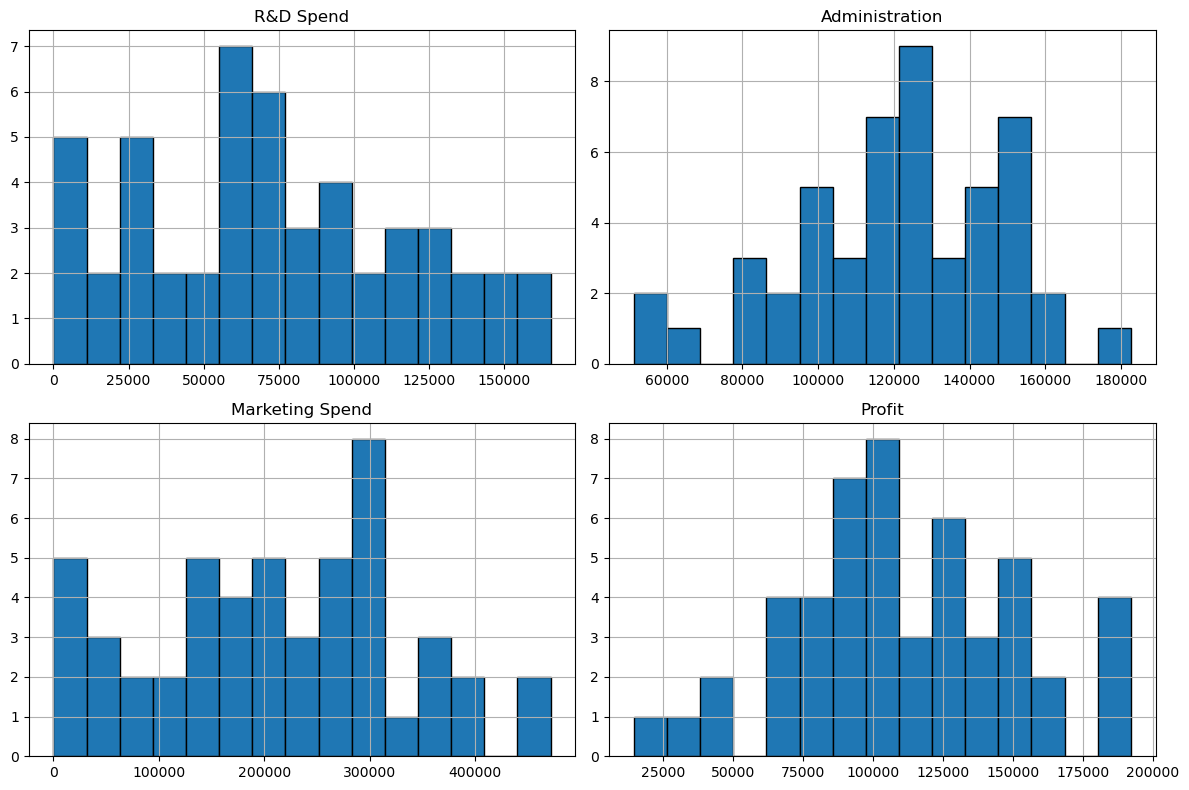

In [10]:
startup_df.select_dtypes(include='number').hist(
    figsize=(12, 8),
    bins=15,
    edgecolor='black'
)

plt.tight_layout()
plt.show()

### Notes

- R&D: Values range from 0-165000. Not perfectly distributed but not skewed either. There are multiple concentrations.
- Adminstration: Values are concentrated between 100000 and 160000. There are some observations at the upper and lower ends.
- Marketing Spend: Values range from 0-over400000. This will need to be further investigated to determine whether marketing spending affects profits.
- Profit: Values range form around 15000-190000. This is a large range of profits. Relationships with Profit need to be determined. 

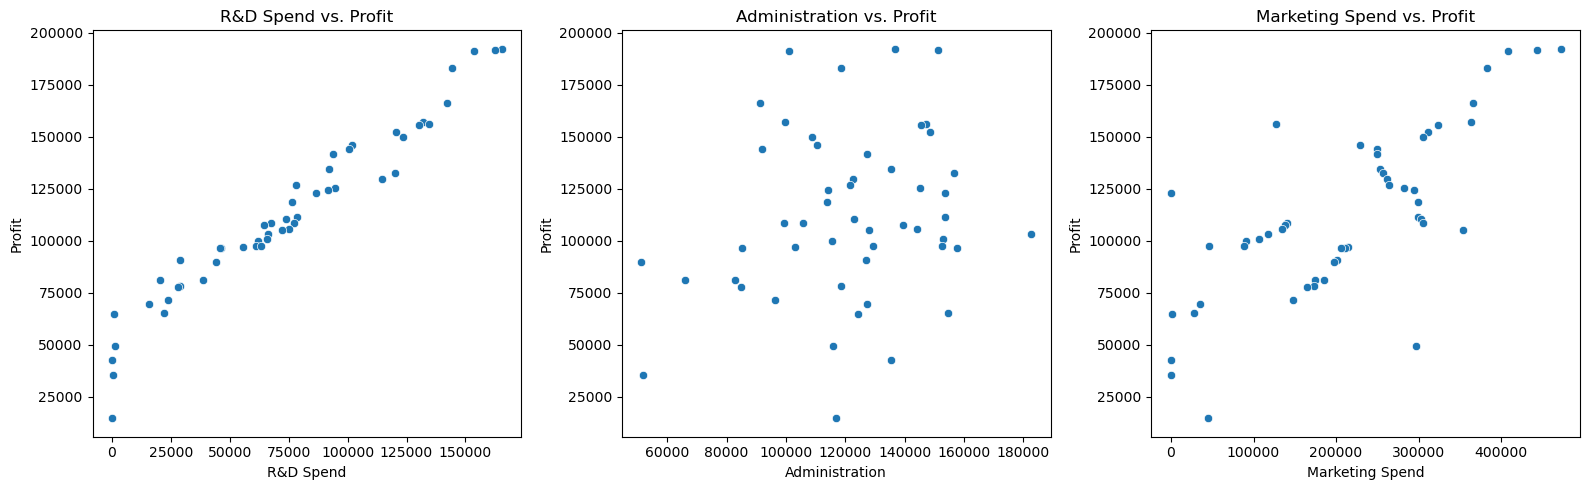

In [11]:
spending_columns = [
    'R&D Spend',
    'Administration',
    'Marketing Spend'
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, column in zip(axes, spending_columns):
    sns.scatterplot(
        data=startup_df,
        x=column,
        y='Profit',
        ax=ax
    )
    ax.set_title(f'{column} vs. Profit')

plt.tight_layout()
plt.show()

### Notes

Relationships with profit:
- R&D: Nearly linear positive relationship. Probably a useful predictor.
- Administration: Not an obvious linear relationship. May not be a useful predictor.
- Marketing Spend: There is some bit of positive relationship but with points all over the place it will need to be explored further.


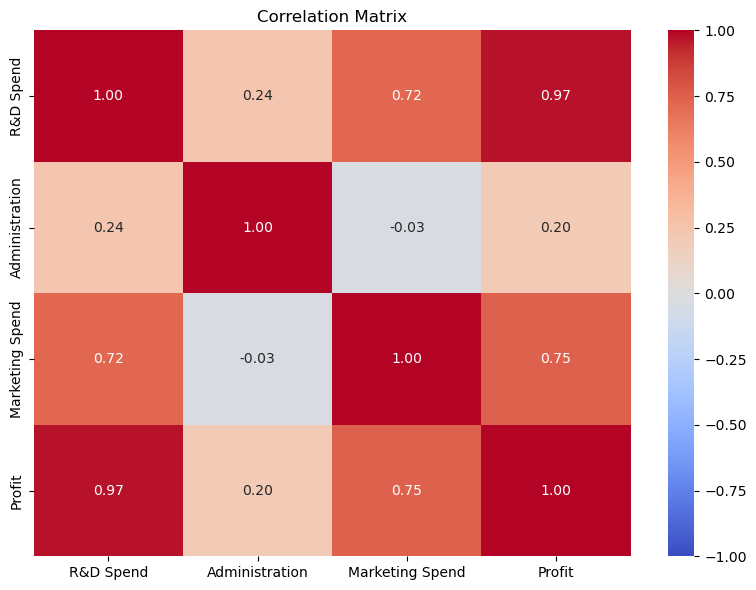

In [12]:
correlation_matrix = startup_df.select_dtypes(
    include='number'
).corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

### Notes

R&D Spend and Marketing have the strongest linear associations with Profit. Adminstration was much weaker, like previously stated. 

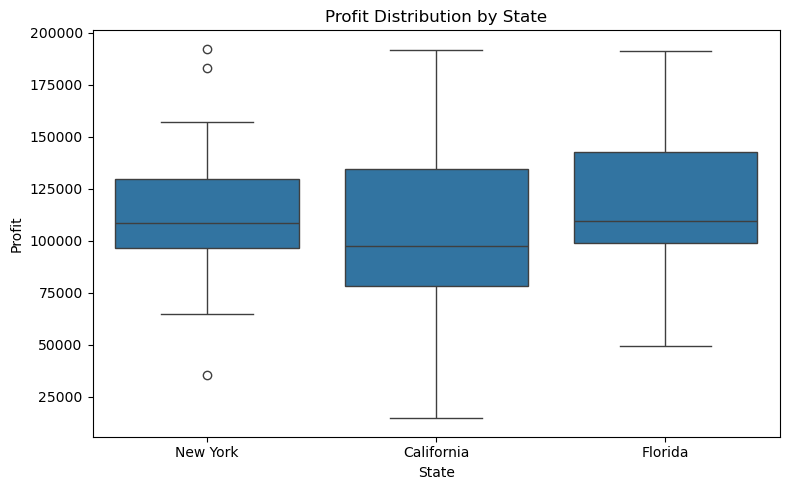

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=startup_df,
    x='State',
    y='Profit'
)

plt.title('Profit Distribution by State')
plt.tight_layout()
plt.show()

## Feature Engineering

The dataset needs to be prepared for regression modeling. All variables should be in a numerical format. The data should be organized and structured appropriately for modeling. 

The following are the feature engineering steps I will be taking:
- Select predictors and target variables
- Encode 'State'
- Create X and y

In [14]:
predictor_columns = [
    'R&D Spend',
    'Administration',
    'Marketing Spend',
    'State'
]

target_column = 'Profit'
    

In [15]:
startup_df = pd.get_dummies(
    startup_df,
    columns=['State'],
    drop_first=True,
    dtype=int
)

startup_df.head()

,R&D Spend,Administration,Marketing Spend,Profit,State_Florida,State_New York
0,165349.20,136897.80,471784.10,192261.83,0,1
1,162597.70,151377.59,443898.53,191792.06,0,0
2,153441.51,101145.55,407934.54,191050.39,1,0
3,144372.41,118671.85,383199.62,182901.99,0,1
4,142107.34,91391.77,366168.42,166187.94,1,0


In [16]:
X = startup_df.drop(columns=['Profit'])
y = startup_df['Profit']

## Train/Test Split

The dataset will be divided into training and testing datasets. The training dataset will be used to fit the regression model and perform hyperparameter tuning. Then the test dataset will be used to evaluate the final model. I will be using an 80/20 split.

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [24]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((40, 5), (10, 5), (40,), (10,))

## Build Regression Model

A Ridge Regression Model will be used to predict the target variable 'Profit'. X and y have already been defined.

In [29]:

from sklearn.linear_model import Ridge

ridge_model = Ridge()

ridge_model.fit(X_train, y_train)

y_train_pred = ridge_model.predict(X_train)

## Evaluate the Model

I will be using MAE and RMSE to evaluate the model at this point. 

In [30]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

mae = mean_absolute_error(y_train, y_train_pred)
rmse = root_mean_squared_error(y_train, y_train_pred)

mae, rmse


(6655.4599147903355, 8927.628507042164)

### Notes

The model produced an MAE of approximately 6655.46 and an RMSE of approximately 8927.63 on the training data. 

MAE shows the model's predictions differ from the actual profit by an average absolute amount of about $6655. RMSE may indicate that larger prediction errors are influencing the overall error. 

## Hyperparameter Tuning 

Cross-validation will be used on the training dataset. MAE will be used to determine the best value for value. 

In [31]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'alpha': [0.01, 0.1, 1, 10, 100, 1000]
}

In [32]:
ridge_search = GridSearchCV(
    estimator=ridge_model,
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=5
)

ridge_search.fit(X_train, y_train)

print(f'Best alpha: {ridge_search.best_params_['alpha']}')
print(f'Best cross-validation MAE: {-ridge_search.best_score_}')

Best alpha: 1000
Best cross-validation MAE: 7394.6614683384805


In [33]:
param_grid = {
    'alpha': [100, 1000, 10000, 100000]
}

ridge_search = GridSearchCV(
    estimator=ridge_model,
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=5
)

ridge_search.fit(X_train, y_train)

print(f'Best alpha: {ridge_search.best_params_['alpha']}')
print(f'Best cross-validation MAE: {-ridge_search.best_score_}')

Best alpha: 100000
Best cross-validation MAE: 7390.739730592407


In [34]:
param_grid = {
    'alpha': [10000, 100000, 1000000, 10000000]
}

ridge_search = GridSearchCV(
    estimator=ridge_model,
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=5
)

ridge_search.fit(X_train, y_train)

print(f'Best alpha: {ridge_search.best_params_['alpha']}')
print(f'Best cross-validation MAE: {-ridge_search.best_score_}')

Best alpha: 100000
Best cross-validation MAE: 7390.739730592407


In [36]:
best_ridge_model = ridge_search.best_estimator_


## Final Model Evaluation

For final evaluation a baseline MLR model will be compared to the tuned Ridge Regression model using the unseen test dataset. 

In [37]:
from sklearn.linear_model import LinearRegression

mlr_model = LinearRegression()
mlr_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 0.81, -0.07, 0.03,938.79, 6.99]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['R&D Spend','Administration','Marketing Spend','State_Florida', 'State_New York']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.403e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,5


In [39]:
mlr_test_pred = mlr_model.predict(X_test)

ridge_test_pred = best_ridge_model.predict(X_test)

results = pd.DataFrame({
    'Model': ['Multiple Linear Regression', 'Tuned Ridge Regression'],
    'MAE': [
        mean_absolute_error(y_test, mlr_test_pred),
        mean_absolute_error(y_test, ridge_test_pred)
    ],
    'RMSE': [
        root_mean_squared_error(y_test, mlr_test_pred),
        root_mean_squared_error(y_test, ridge_test_pred)
    ]
})

print(results.round(2))

                        Model      MAE     RMSE
0  Multiple Linear Regression  6961.48  9055.96
1      Tuned Ridge Regression  6979.16  8995.92


### Notes

Both models performed fairly similarly with the test data. The MLR performed slightly better based on the MAE and the Ridge Regression model performed slightly better based on the RMSE. Neither model shows clear advantage. 